#Task 1 – Data Exploration & Preprocessing

In [6]:
import pandas as pd

url ="https://raw.githubusercontent.com/karthi-95Entri/M4A8-Clustering-and-Dimensionality-Reduction/refs/heads/main/mall_customer_spend.xlsx"
df = pd.read_excel(url)
print(df)


     CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


In [7]:

print("SHAPE::::")
print(df.shape)
print(f'')
print(" COLUMNS::::")
print(f'')
print(df.columns)
print(f'')
print(" INFO")
print(f'')
print(df.info())
print(f'')
print("DATA TYPES")
print(f'')
print(df.dtypes)
print(f'')
df.isnull().sum()

SHAPE::::
(200, 5)

 COLUMNS::::

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

 INFO

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

DATA TYPES

CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object



,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


#Lable Encoding for Gender column

In [8]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

url ="https://raw.githubusercontent.com/karthi-95Entri/M4A8-Clustering-and-Dimensionality-Reduction/refs/heads/main/mall_customer_spend.xlsx"
df = pd.read_excel(url)


le = LabelEncoder()

df["Genre"] = le.fit_transform(df["Genre"].astype(str))
print("Genre mapping:")
print(dict(zip(le.classes_, le.transform(le.classes_))))
print(df)

Genre mapping:
{'Female': np.int64(0), 'Male': np.int64(1)}
     CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)
0             1      1   19                  15                      39
1             2      1   21                  15                      81
2             3      0   20                  16                       6
3             4      0   23                  16                      77
4             5      0   31                  17                      40
..          ...    ...  ...                 ...                     ...
195         196      0   35                 120                      79
196         197      0   45                 126                      28
197         198      1   32                 126                      74
198         199      1   32                 137                      18
199         200      1   30                 137                      83

[200 rows x 5 columns]


In [9]:

import pandas as pd


print("Available Columns:")
print(df.columns.tolist())

numeric_df = df.select_dtypes(include="number")
print("\nNumerical Columns:")
print(numeric_df.columns.tolist())


features = numeric_df.drop(
    columns=["CustomerID"],
    errors="ignore"
)

print("\nSelected Features for Clustering:")
print(features.head())

print("\nShape of Selected Features:", features.shape)


features = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print(features.head())


Available Columns:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Numerical Columns:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Selected Features for Clustering:
   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0      1   19                  15                      39
1      1   21                  15                      81
2      0   20                  16                       6
3      0   23                  16                      77
4      0   31                  17                      40

Shape of Selected Features: (200, 4)
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


#Scale numerical features appropriately

In [10]:

from sklearn.preprocessing import StandardScaler
import pandas as pd


features = df.select_dtypes(include="number").drop(
    columns=["CustomerID"],
    errors="ignore"
)


features = features.fillna(features.median())


scaler = StandardScaler()


scaled_data = scaler.fit_transform(features)


scaled_df = pd.DataFrame(
    scaled_data,
    columns=features.columns,
    index=features.index
)


print("Scaled Features:")
print(scaled_df.head())

print("\nScaled Data Shape:", scaled_df.shape)


Scaled Features:
      Genre       Age  Annual Income (k$)  Spending Score (1-100)
0  1.128152 -1.424569           -1.738999               -0.434801
1  1.128152 -1.281035           -1.738999                1.195704
2 -0.886405 -1.352802           -1.700830               -1.715913
3 -0.886405 -1.137502           -1.700830                1.040418
4 -0.886405 -0.563369           -1.662660               -0.395980

Scaled Data Shape: (200, 4)


#Task 2 – K-Means Clustering

In [11]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(scaled_df)

print(df.head())


print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster Centers:")
print(kmeans.cluster_centers_)


   CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1      1   19                  15                      39        0
1           2      1   21                  15                      81        0
2           3      0   20                  16                       6        1
3           4      0   23                  16                      77        0
4           5      0   31                  17                      40        1

Customers in Each Cluster:
Cluster
0    85
1    66
2    49
Name: count, dtype: int64

Cluster Centers:
[[ 0.03792108 -0.77529133  0.04688104  0.88056434]
 [-0.88640526  0.44680201 -0.10812358 -0.5442077 ]
 [ 1.12815215  0.74307816  0.06431159 -0.79449512]]



# Demonstrate the Random Initialization Trap

Results with Different Random Initializations:
   Random Seed     Inertia
0            0  484.825560
1            1  514.716478
2           10  496.430241
3           20  488.037339
4           42  487.737624


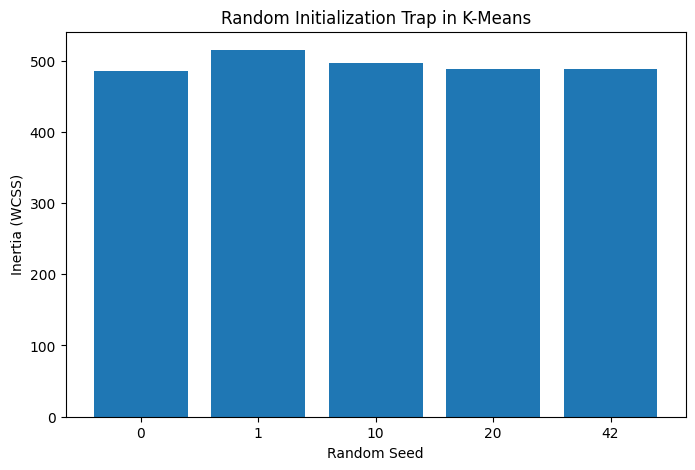

In [12]:

from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt


seeds = [0, 1, 10, 20, 42]
results = []
for seed in seeds:
    kmeans = KMeans(
        n_clusters=3,
        init="random",
        n_init=1,
        random_state=seed
    )

    kmeans.fit(scaled_df)

    results.append({
        "Random Seed": seed,
        "Inertia": kmeans.inertia_
    })


results_df = pd.DataFrame(results)

print("Results with Different Random Initializations:")
print(results_df)
plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Random Seed"].astype(str),
    results_df["Inertia"]
)
plt.title("Random Initialization Trap in K-Means")
plt.xlabel("Random Seed")
plt.ylabel("Inertia (WCSS)")
plt.show()



#Use the Elbow Method to determine the optimal number of clusters

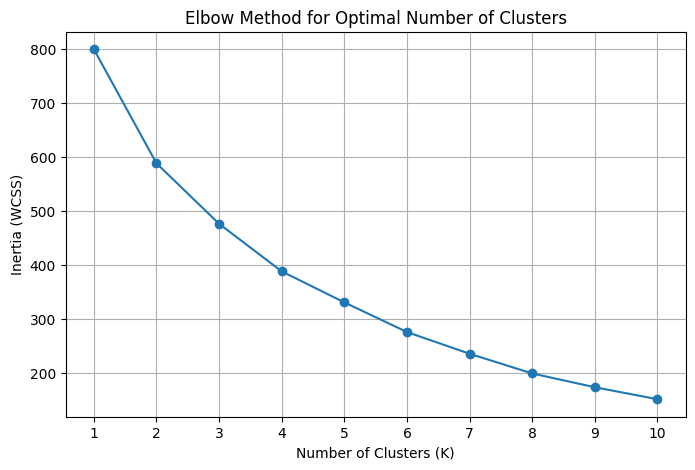

In [13]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(scaled_df)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()


# Build the final K-Means model

In [14]:

from sklearn.cluster import KMeans
import pandas as pd


optimal_k = 3
final_kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

df["Cluster"] = final_kmeans.fit_predict(scaled_df)

print("Final K-Means Model")
print("Number of clusters:", optimal_k)
print("Inertia:", final_kmeans.inertia_)

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster Centers (Scaled Features):")
print(final_kmeans.cluster_centers_)

print("\nDataset with Cluster Labels:")
print(df.head())


Final K-Means Model
Number of clusters: 3
Inertia: 476.78755441351575

Customers in Each Cluster:
Cluster
0    85
1    66
2    49
Name: count, dtype: int64

Cluster Centers (Scaled Features):
[[ 0.03792108 -0.77529133  0.04688104  0.88056434]
 [-0.88640526  0.44680201 -0.10812358 -0.5442077 ]
 [ 1.12815215  0.74307816  0.06431159 -0.79449512]]

Dataset with Cluster Labels:
   CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1      1   19                  15                      39        0
1           2      1   21                  15                      81        0
2           3      0   20                  16                       6        1
3           4      0   23                  16                      77        0
4           5      0   31                  17                      40        1


#Task 3 – Hierarchical Clustering


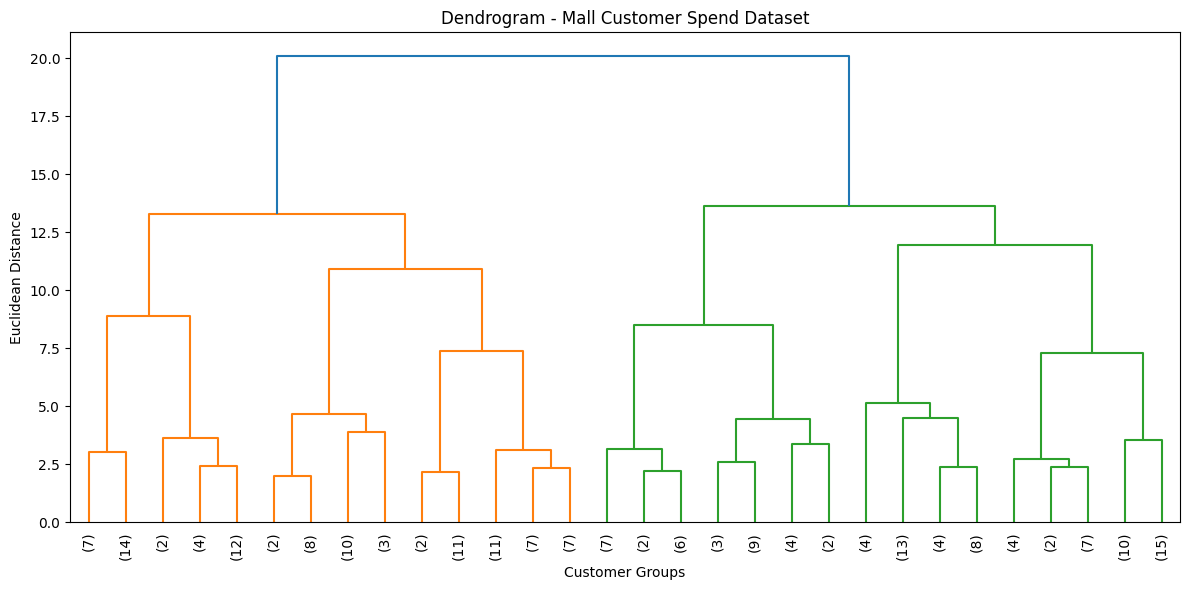

In [15]:

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

hierarchical = linkage(scaled_df, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(
    hierarchical,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Dendrogram - Mall Customer Spend Dataset")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()


In [16]:

from sklearn.cluster import AgglomerativeClustering
import pandas as pd


optimal_k = 3

agg_model = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage="ward"
)


agg_labels = agg_model.fit_predict(scaled_df)


df["Agg_Cluster"] = agg_labels

print("First 5 rows with cluster labels:")
print(df.head())

print("\nNumber of customers in each cluster:")
print(df["Agg_Cluster"].value_counts().sort_index())


First 5 rows with cluster labels:
   CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1      1   19                  15                      39   
1           2      1   21                  15                      81   
2           3      0   20                  16                       6   
3           4      0   23                  16                      77   
4           5      0   31                  17                      40   

   Cluster  Agg_Cluster  
0        0            0  
1        0            0  
2        1            1  
3        0            0  
4        1            1  

Number of customers in each cluster:
Agg_Cluster
0    100
1     67
2     33
Name: count, dtype: int64


K-Means Cluster Sizes:
KMeans_Cluster
0    85
1    66
2    49
Name: count, dtype: int64

Hierarchical Cluster Sizes:
Hierarchical_Cluster
0    100
1     67
2     33
Name: count, dtype: int64

Model Comparison:
      Algorithm  Silhouette Score
0       K-Means             0.260
1  Hierarchical             0.248


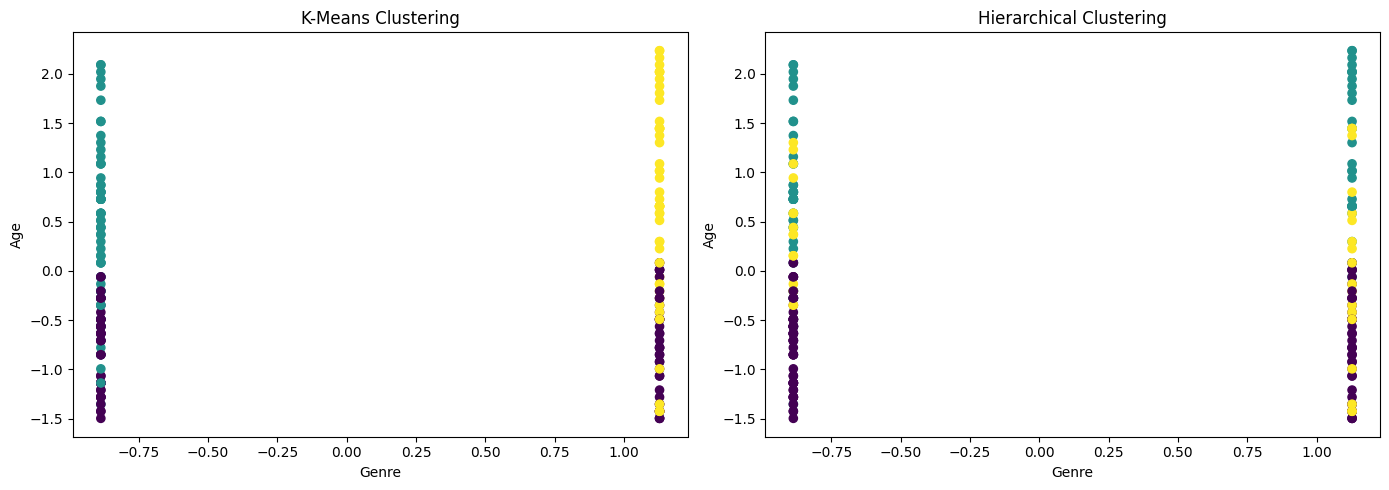

In [17]:

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt


optimal_k = 3


kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)
kmeans_labels = kmeans.fit_predict(scaled_df)


hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(scaled_df)


df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels


print("K-Means Cluster Sizes:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nHierarchical Cluster Sizes:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())


comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Silhouette Score": [
        silhouette_score(scaled_df, kmeans_labels),
        silhouette_score(scaled_df, hierarchical_labels)
    ]
})

print("\nModel Comparison:")
print(comparison.round(3))


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


x_col, y_col = scaled_df.columns[:2]

axes[0].scatter(
    scaled_df[x_col], scaled_df[y_col],
    c=kmeans_labels, cmap="viridis", s=35
)
axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel(x_col)
axes[0].set_ylabel(y_col)

axes[1].scatter(
    scaled_df[x_col], scaled_df[y_col],
    c=hierarchical_labels, cmap="viridis", s=35
)
axes[1].set_title("Hierarchical Clustering")
axes[1].set_xlabel(x_col)
axes[1].set_ylabel(y_col)

plt.tight_layout()
plt.show()


#Task 4 – DBSCAN Clustering


In [18]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt


dbscan = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="euclidean"
)

dbscan_labels = dbscan.fit_predict(scaled_df)


df["DBSCAN_Cluster"] = dbscan_labels


print("DBSCAN Cluster Counts:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())


n_clusters = len(set(dbscan_labels) - {-1})
n_noise = (dbscan_labels == -1).sum()

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)


non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(
        scaled_df.loc[non_noise_mask],
        non_noise_labels
    )
    print("Silhouette Score (excluding noise):", round(score, 3))
else:
    print("Silhouette score cannot be calculated: fewer than 2 non-noise clusters.")


DBSCAN Cluster Counts:
DBSCAN_Cluster
-1    105
 0      5
 1      5
 2     18
 3     18
 4     15
 5      7
 6      4
 7     17
 8      6
Name: count, dtype: int64

Number of clusters: 9
Number of noise points: 105
Silhouette Score (excluding noise): 0.54


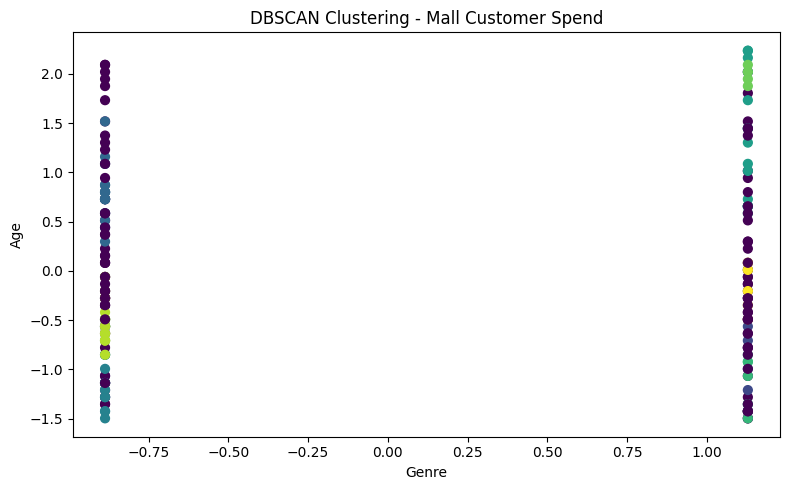

In [19]:

plt.figure(figsize=(8, 5))

plt.scatter(
    scaled_df.iloc[:, 0],
    scaled_df.iloc[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=40
)

plt.title("DBSCAN Clustering - Mall Customer Spend")
plt.xlabel(scaled_df.columns[0])
plt.ylabel(scaled_df.columns[1])
plt.tight_layout()
plt.show()


# Identify clusters and noise points

In [20]:

import pandas as pd
import numpy as np

df["DBSCAN_Cluster"] = dbscan_labels


cluster_labels = sorted(
    label for label in df["DBSCAN_Cluster"].unique()
    if label != -1
)

print("Identified Clusters:", cluster_labels)
print("Number of Clusters:", len(cluster_labels))


print("\nCustomers in Each Cluster:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())


noise_points = df[df["DBSCAN_Cluster"] == -1]

print("\nNumber of Noise Points:", len(noise_points))
print("\nNoise Points:")
print(noise_points)


noise_percentage = len(noise_points) / len(df) * 100

print(f"\nNoise Percentage: {noise_percentage:.2f}%")


for cluster in cluster_labels:
    members = df[df["DBSCAN_Cluster"] == cluster]
    print(f"\nCluster {cluster}: {len(members)} customers")
    print(members.head())


Identified Clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Number of Clusters: 9

Customers in Each Cluster:
DBSCAN_Cluster
-1    105
 0      5
 1      5
 2     18
 3     18
 4     15
 5      7
 6      4
 7     17
 8      6
Name: count, dtype: int64

Number of Noise Points: 105

Noise Points:
     CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1      1   19                  15                      39   
1             2      1   21                  15                      81   
2             3      0   20                  16                       6   
4             5      0   31                  17                      40   
6             7      0   35                  18                       6   
..          ...    ...  ...                 ...                     ...   
195         196      0   35                 120                      79   
196         197      0   4

#Compare DBSCAN results with K-Means and Hierarchical Clustering

In [21]:

import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score


optimal_k = 3


kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)
kmeans_labels = kmeans.fit_predict(scaled_df)


hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(scaled_df)


dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(scaled_df)


df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels
df["DBSCAN_Cluster"] = dbscan_labels


def evaluate_clustering(name, labels, exclude_noise=False):
    labels = pd.Series(labels, index=scaled_df.index)

    mask = labels != -1 if exclude_noise else pd.Series(
        True, index=labels.index
    )

    valid_labels = labels[mask]
    valid_data = scaled_df.loc[mask]

    n_clusters = valid_labels.nunique()
    n_noise = (labels == -1).sum() if exclude_noise else 0

    if 1 < n_clusters < len(valid_labels):
        score = silhouette_score(valid_data, valid_labels)
    else:
        score = None

    return {
        "Algorithm": name,
        "Number of Clusters": labels[labels != -1].nunique(),
        "Noise Points": n_noise,
        "Silhouette Score": round(score, 3) if score is not None else "N/A"
    }


results = [
    evaluate_clustering("K-Means", kmeans_labels),
    evaluate_clustering("Hierarchical", hierarchical_labels),
    evaluate_clustering("DBSCAN", dbscan_labels, exclude_noise=True)
]

comparison_df = pd.DataFrame(results)

print("Clustering Algorithm Comparison:")
print(comparison_df.to_string(index=False))


print("\nK-Means Cluster Sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nHierarchical Cluster Sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

print("\nDBSCAN Cluster Sizes (including noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())


Clustering Algorithm Comparison:
   Algorithm  Number of Clusters  Noise Points  Silhouette Score
     K-Means                   3             0             0.260
Hierarchical                   3             0             0.248
      DBSCAN                   9           105             0.540

K-Means Cluster Sizes:
0    85
1    66
2    49
Name: count, dtype: int64

Hierarchical Cluster Sizes:
0    100
1     67
2     33
Name: count, dtype: int64

DBSCAN Cluster Sizes (including noise):
-1    105
 0      5
 1      5
 2     18
 3     18
 4     15
 5      7
 6      4
 7     17
 8      6
Name: count, dtype: int64


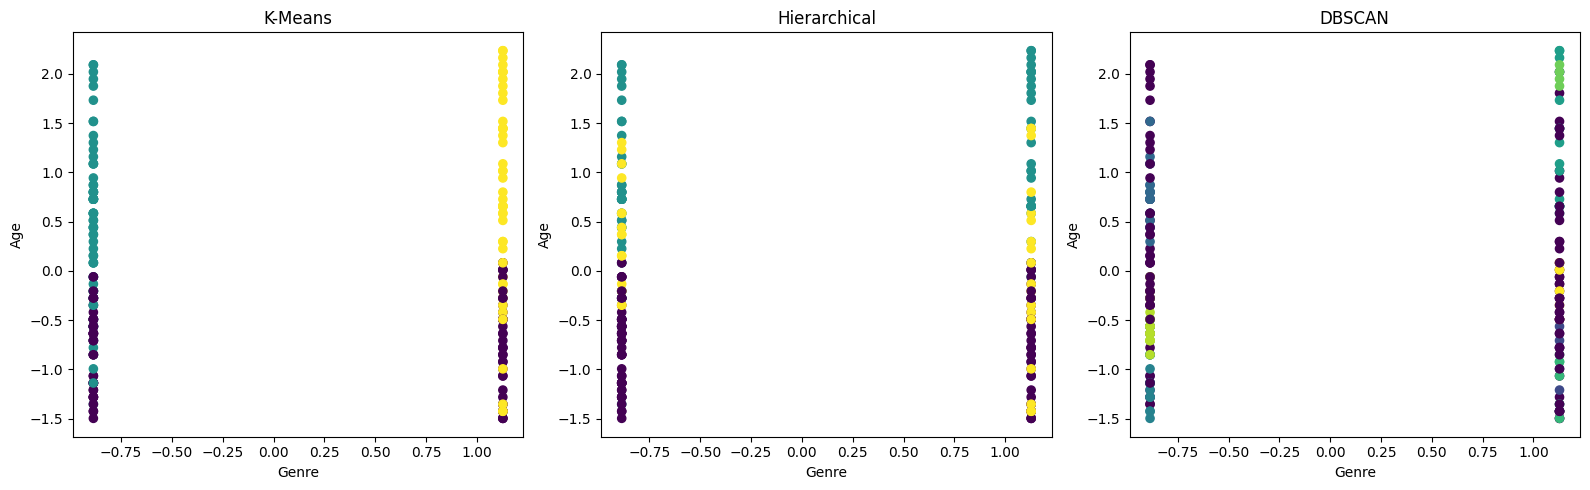

In [22]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels_list = [
    ("K-Means", kmeans_labels),
    ("Hierarchical", hierarchical_labels),
    ("DBSCAN", dbscan_labels)
]

for ax, (name, labels) in zip(axes, labels_list):
    ax.scatter(
        scaled_df.iloc[:, 0],
        scaled_df.iloc[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )
    ax.set_title(name)
    ax.set_xlabel(scaled_df.columns[0])
    ax.set_ylabel(scaled_df.columns[1])

plt.tight_layout()
plt.show()


#Task 5 – Dimensionality Reduction

# Apply PCA to reduce dimensionality

In [23]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_df)


pca_df = pd.DataFrame(
    pca_data,
    columns=["Principal Component 1", "Principal Component 2"],
    index=scaled_df.index
)

print("PCA Results:")
print(pca_df.head())

print("\nOriginal Number of Features:", scaled_df.shape[1])
print("Reduced Number of Features:", pca_df.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


PCA Results:
   Principal Component 1  Principal Component 2
0              -0.406383              -0.520714
1              -1.427673              -0.367310
2               0.050761              -1.894068
3              -1.694513              -1.631908
4              -0.313108              -1.810483

Original Number of Features: 4
Reduced Number of Features: 2

Explained Variance Ratio:
[0.33690046 0.26230645]

Total Variance Explained: 59.92 %


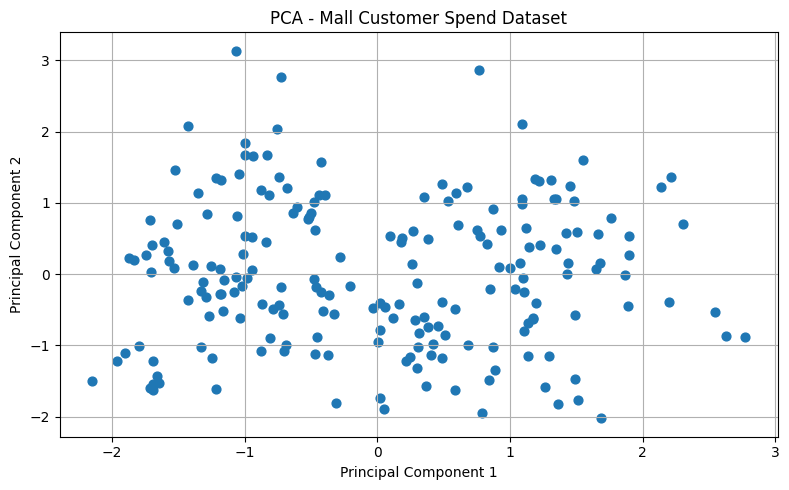

In [24]:

plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"],
    s=40
)

plt.title("PCA - Mall Customer Spend Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()


#Apply t-SNE for low-dimensional representation

In [25]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

perplexity_value = min(30, len(scaled_df) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    learning_rate="auto",
    init="pca",
    random_state=42
)

tsne_data = tsne.fit_transform(scaled_df)

tsne_df = pd.DataFrame(
    tsne_data,
    columns=["t-SNE 1", "t-SNE 2"],
    index=scaled_df.index
)

print("t-SNE Results:")
print(tsne_df.head())

print("\nOriginal Features:", scaled_df.shape[1])
print("Reduced Features:", tsne_df.shape[1])


t-SNE Results:
    t-SNE 1    t-SNE 2
0  2.425970  -7.152119
1  3.042494  -5.478380
2 -4.405653  14.091286
3 -7.819345  12.497788
4 -4.630795  12.384195

Original Features: 4
Reduced Features: 2


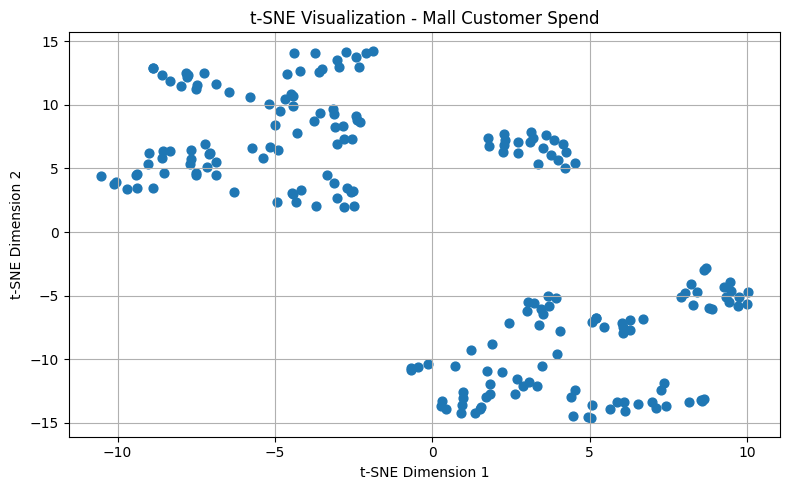

In [26]:

plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_df["t-SNE 1"],
    tsne_df["t-SNE 2"],
    s=40
)

plt.title("t-SNE Visualization - Mall Customer Spend")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(True)
plt.tight_layout()
plt.show()


t-SNE provides a two-dimensional visualization of customer similarities, making it easier to explore potential clusters. Use it alongside PCA and clustering evaluation metrics rather than treating the visual separation alone as proof of cluster quality.

#Compare insights obtained from PCA and t-SNE



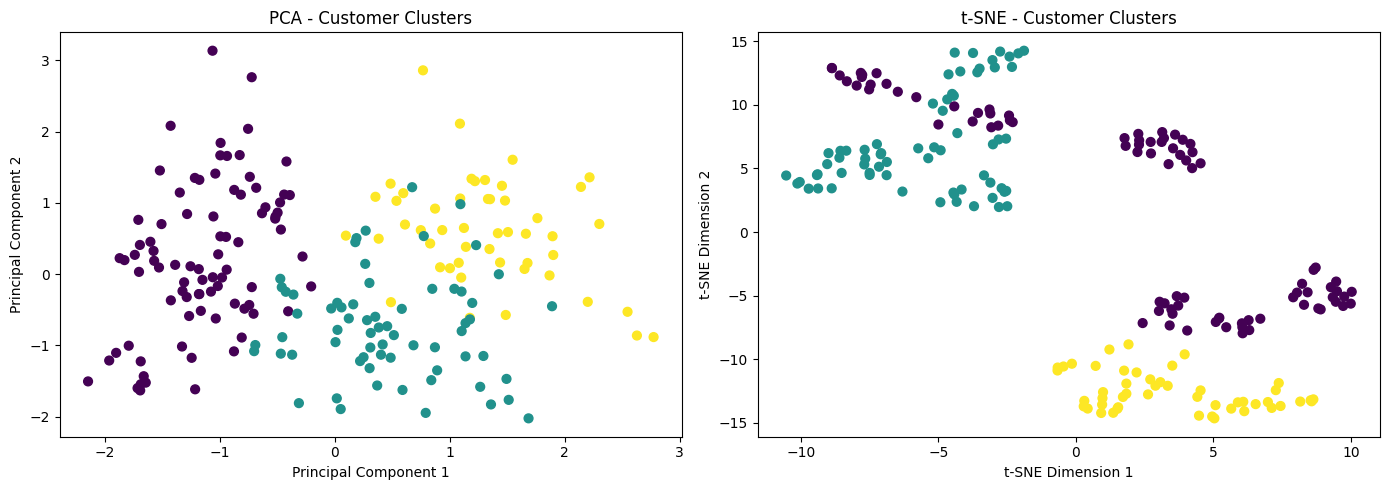

PCA variance explained: 59.92 %


In [27]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"],
    c=kmeans_labels,
    cmap="viridis",
    s=40
)
axes[0].set_title("PCA - Customer Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")


axes[1].scatter(
    tsne_df["t-SNE 1"],
    tsne_df["t-SNE 2"],
    c=kmeans_labels,
    cmap="viridis",
    s=40
)
axes[1].set_title("t-SNE - Customer Clusters")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


#Task 6 – Cluster Analysis


#Analyze customer characteristics within each cluster

In [28]:

import pandas as pd
df["Cluster"] = kmeans_labels
numeric_cols = df.select_dtypes(include="number").columns.tolist()
exclude_cols = [
    "CustomerID", "Customer ID", "ID",
    "Cluster", "KMeans_Cluster",
    "Hierarchical_Cluster", "Agg_Cluster",
    "DBSCAN_Cluster"
]

profile_cols = [
    col for col in numeric_cols
    if col not in exclude_cols
]


cluster_means = df.groupby("Cluster")[profile_cols].mean()

print("Average Customer Characteristics by Cluster:")
print(cluster_means.round(2))

cluster_medians = df.groupby("Cluster")[profile_cols].median()

print("\nMedian Customer Characteristics by Cluster:")
print(cluster_medians.round(2))

print("\nNumber of Customers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())


cluster_profile = cluster_means.copy()
cluster_profile.insert(
    0, "Customer_Count",
    df.groupby("Cluster").size()
)

print("\nComplete Cluster Profile:")
print(cluster_profile.round(2))


Average Customer Characteristics by Cluster:
         Genre    Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                          
0         0.46  28.05               61.79                   72.88
1         0.00  45.08               57.73                   36.18
2         1.00  49.20               62.24                   29.73

Median Customer Characteristics by Cluster:
         Genre   Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                         
0          0.0  29.0                64.0                    75.0
1          0.0  46.0                55.5                    40.0
2          1.0  48.0                62.0                    35.0

Number of Customers in Each Cluster:
Cluster
0    85
1    66
2    49
Name: count, dtype: int64

Complete Cluster Profile:
         Customer_Count  Genre    Age  Annual Income (k$)  \
Cluster                                                     
0         

# Identify meaningful customer segments

Customer Cluster Profiles:
         Customer_Count  Avg_Income  Avg_Spending
Cluster                                          
0                    85       61.79         72.88
1                    66       57.73         36.18
2                    49       62.24         29.73

Meaningful Customer Segments:
         Customer_Count  Avg_Income  Avg_Spending             Customer_Segment
Cluster                                                                       
0                    85       61.79         72.88  High Income - High Spending
1                    66       57.73         36.18    Low Income - Low Spending
2                    49       62.24         29.73   High Income - Low Spending


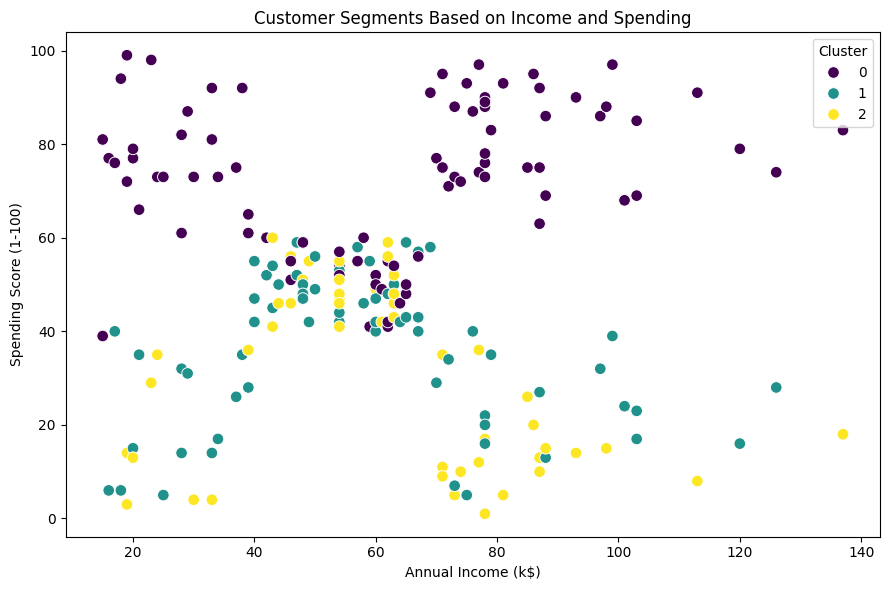

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Avg_Income=("Annual Income (k$)", "mean"),
    Avg_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Profiles:")
print(cluster_profile)


income_median = df["Annual Income (k$)"].median()
spending_median = df["Spending Score (1-100)"].median()


def identify_segment(row):
    high_income = row["Avg_Income"] >= income_median
    high_spending = row["Avg_Spending"] >= spending_median

    if high_income and high_spending:
        return "High Income - High Spending"
    elif high_income and not high_spending:
        return "High Income - Low Spending"
    elif not high_income and high_spending:
        return "Low Income - High Spending"
    else:
        return "Low Income - Low Spending"

cluster_profile["Customer_Segment"] = cluster_profile.apply(
    identify_segment, axis=1
)

print("\nMeaningful Customer Segments:")
print(cluster_profile)


plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title("Customer Segments Based on Income and Spending")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()


#Provide business recommendations based on the clusters

In [31]:
recommendations = {
    "High Income - High Spending":
        "Offer VIP memberships, premium products, and exclusive loyalty rewards.",

    "High Income - Low Spending":
        "Use personalized promotions and targeted campaigns to increase engagement.",

    "Low Income - High Spending":
        "Provide bundle deals, loyalty points, and value-added offers.",

    "Low Income - Low Spending":
        "Promote affordable products, seasonal discounts, and budget-friendly bundles."
}

cluster_profile["Business_Recommendation"] = (
    cluster_profile["Customer_Segment"].map(recommendations)
)

print("Customer Segments and Business Recommendations:")
print(
    cluster_profile[
        [
            "Customer_Count",
            "Avg_Income",
            "Avg_Spending",
            "Customer_Segment",
            "Business_Recommendation"
        ]
    ].to_string()
)


Customer Segments and Business Recommendations:
         Customer_Count  Avg_Income  Avg_Spending             Customer_Segment                                                        Business_Recommendation
Cluster                                                                                                                                                      
0                    85       61.79         72.88  High Income - High Spending        Offer VIP memberships, premium products, and exclusive loyalty rewards.
1                    66       57.73         36.18    Low Income - Low Spending  Promote affordable products, seasonal discounts, and budget-friendly bundles.
2                    49       62.24         29.73   High Income - Low Spending     Use personalized promotions and targeted campaigns to increase engagement.
